# 02 · Análisis Detallado — Mercado Formal (Concesionarios e Importadoras)

**Notebook de apoyo (Fase 5 - EDA)**

Este notebook analiza el mercado formal de automóviles en La Habana, a partir de los datos de concesionarias e importadoras, y los catálogos scrapeados de Dongfeng Cuba y BDC ONE.

| Dataset | Registros | Archivo |
|---|---|---|
| Mercado formal (entidades) | 10 entidades | `data/processed_final/mercado_formal_final.json` |
| Catálogos scrapeados | 3 entidades / 65 modelos | `data/raw/catalogos_mercado_formal.json` |

## 1. Librerías y configuración

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

FIG_DIR = Path("reports") / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PROC = BASE / "data" / "processed_final"
DATA_RAW = BASE / "data" / "raw"

def cargar_json(ruta):
    with open(ruta, encoding="utf-8") as archivo:
        return json.load(archivo)

formal = cargar_json(DATA_PROC / "mercado_formal_final.json")
catalogos = cargar_json(DATA_RAW / "catalogos_mercado_formal.json")

df_formal = pd.DataFrame(formal)
print("Entidades del mercado formal:", len(df_formal))
print("Columnas:", list(df_formal.columns))

Entidades del mercado formal: 10
Columnas: ['id_entidad', 'nombre', 'nombre_normalizado', 'tipo_entidad', 'marcas_comercializadas', 'modelos_disponibles', 'tipos_vehiculos', 'vehiculos_electricos', 'informacion_importacion', 'precios', 'ubicacion', 'sitio_web', 'contacto_publico', 'descripcion', 'fuentes', 'fecha_ultima_verificacion', 'nivel_confianza', 'observaciones', 'enriquecimiento_catalogos']


## 2. Análisis de entidades

In [2]:
print("=== ENTIDADES POR TIPO ===")
print(df_formal["tipo_entidad"].value_counts().to_string())

print("\n=== ENTIDADES CON CATÁLOGO vs SIN CATÁLOGO ===")
con_catalogo = df_formal[df_formal["modelos_disponibles"].apply(len) > 0]
sin_catalogo = df_formal[df_formal["modelos_disponibles"].apply(len) == 0]
print("Con catálogo:", len(con_catalogo))
print(con_catalogo[['id_entidad', 'nombre', 'tipo_entidad']].to_string(index=False))
print("\nSin catálogo:", len(sin_catalogo))
print(sin_catalogo[['id_entidad', 'nombre', 'tipo_entidad']].to_string(index=False))

print("\n=== VEHÍCULOS ELÉCTRICOS POR ENTIDAD ===")
for _, r in df_formal.iterrows():
    evs = r['vehiculos_electricos']
    if evs:
        print(r['nombre'] + ': ' + str(len(evs)) + ' eléctricos - ' + ', '.join(evs))
    else:
        print(r['nombre'] + ': 0 eléctricos')

=== ENTIDADES POR TIPO ===
tipo_entidad
comercializadora    4
importadora         4
concesionario       2

=== ENTIDADES CON CATÁLOGO vs SIN CATÁLOGO ===
Con catálogo: 2
   id_entidad        nombre  tipo_entidad
      BDC_ONE       BDC ONE concesionario
DONGFENG_CUBA Dongfeng Cuba concesionario

Sin catálogo: 8
   id_entidad                                                                                               nombre     tipo_entidad
MCV_COMERCIAL                                                                                  MCV Comercial, S.A. comercializadora
         SASA                                                                   Servicios Automotores, S.A. (SASA) comercializadora
        DIVEP                                                                       Empresa Comercializadora DIVEP comercializadora
    IMPEXPORT                                                                                  IMPEXPORT, S.U.R.L.      importadora
    CIMEX_DTA              

## 3. Análisis de catálogos (Dongfeng Cuba y BDC ONE)

In [3]:
print("=== CATÁLOGOS ===")
for entidad in catalogos:
    print('\n' + entidad['nombre_entidad'] + ' (' + entidad['id_entidad'] + ')')
    print('  Accesible:', entidad['accesible'])
    print('  Modelos:', len(entidad['modelos']))
    if entidad['modelos']:
        print('  Motorización: ' + str(dict(Counter(m['motorizacion'] for m in entidad['modelos']))))
        print('  Tipo vehículo: ' + str(dict(Counter(m['tipo_vehiculo'] for m in entidad['modelos']))))
        precios = [m['precio_original'] for m in entidad['modelos'] if m['precio_original']]
        if precios:
            print('  Precio EUR: min=' + str(min(precios)) + ', max=' + str(max(precios)))
            print('  Precio MN: min=' + str(min(p * 1005 for p in precios)) + ', max=' + str(max(p * 1005 for p in precios)))
        evs = [m for m in entidad['modelos'] if m['motorizacion'] == 'electrico' and m.get('autonomia_km')]
        if evs:
            autos = [m['autonomia_km'] for m in evs]
            print('  Autonomía EV: n=' + str(len(autos)) + ', min=' + str(min(autos)) + ', max=' + str(max(autos)) + ' km')
        print('  Modelos sin precio: ' + str(sum(1 for m in entidad['modelos'] if m['precio_original'] is None)))

=== CATÁLOGOS ===

Dongfeng Cuba (DONGFENG_CUBA)
  Accesible: True
  Modelos: 49
  Motorización: {'electrico': 16, 'hibrido': 12, 'gasolina': 10, 'diesel': 11}
  Tipo vehículo: {'SUV': 16, 'Sedán': 4, 'Van': 7, 'Microbús': 5, 'Pickup': 5, 'Camión comercial': 10, 'Familiar': 2}
  Precio EUR: min=15900, max=99000
  Precio MN: min=15979500, max=99495000
  Autonomía EV: n=14, min=220, max=700 km
  Modelos sin precio: 15

BDC ONE (BDC_ONE)
  Accesible: True
  Modelos: 16
  Motorización: {'gasolina': 11, 'electrico': 5}
  Tipo vehículo: {'Hatchback': 4, 'Sedán': 1, 'SUV': 4, 'Monovolumen': 2, 'Minibús': 1, 'Pickup': 2, 'Panel': 1, 'Deportivo': 1}
  Precio EUR: min=14849, max=67135
  Precio MN: min=14923245, max=67470675
  Autonomía EV: n=5, min=216, max=520 km
  Modelos sin precio: 0

MCV Comercial, S.A. (MCV_COMERCIAL)
  Accesible: False
  Modelos: 0


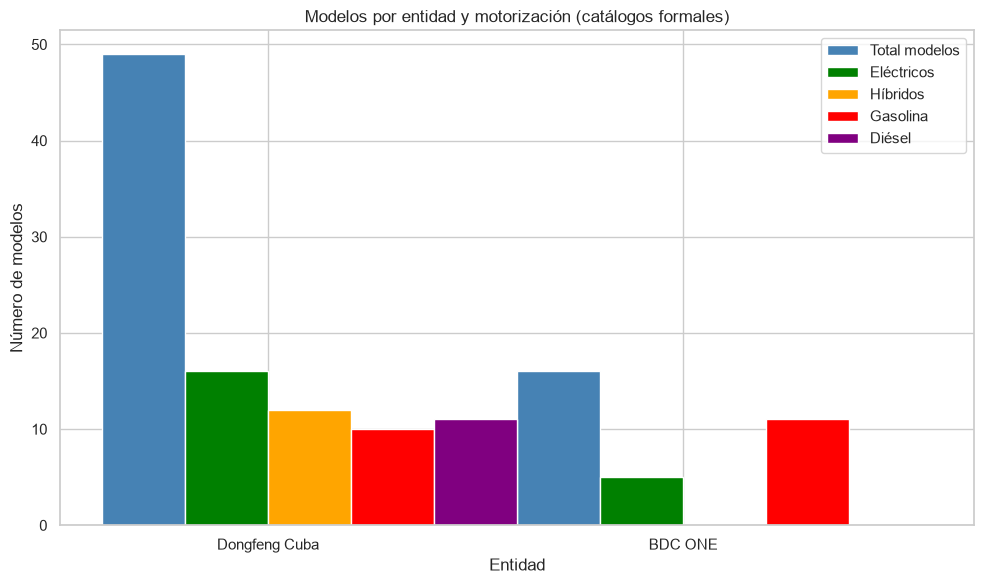

In [4]:
# Gráfico: modelos por entidad y motorización
entidades_con_cat = [e for e in catalogos if e['modelos']]
nombres = [e['nombre_entidad'] for e in entidades_con_cat]
n_modelos = [len(e['modelos']) for e in entidades_con_cat]
n_ev = [sum(1 for m in e['modelos'] if m['motorizacion'] == 'electrico') for e in entidades_con_cat]
n_hib = [sum(1 for m in e['modelos'] if m['motorizacion'] == 'hibrido') for e in entidades_con_cat]
n_gas = [sum(1 for m in e['modelos'] if m['motorizacion'] == 'gasolina') for e in entidades_con_cat]
n_diesel = [sum(1 for m in e['modelos'] if m['motorizacion'] == 'diesel') for e in entidades_con_cat]

fig, ax = plt.subplots(figsize=(10, 6))
x = range(len(nombres))
width = 0.2
ax.bar([i - 1.5*width for i in x], n_modelos, width, label='Total modelos', color='steelblue')
ax.bar([i - 0.5*width for i in x], n_ev, width, label='Eléctricos', color='green')
ax.bar([i + 0.5*width for i in x], n_hib, width, label='Híbridos', color='orange')
ax.bar([i + 1.5*width for i in x], n_gas, width, label='Gasolina', color='red')
ax.bar([i + 2.5*width for i in x], n_diesel, width, label='Diésel', color='purple')
ax.set_xlabel('Entidad')
ax.set_ylabel('Número de modelos')
ax.set_title('Modelos por entidad y motorización (catálogos formales)')
ax.set_xticks(list(x))
ax.set_xticklabels(nombres)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "f07_modelos_por_entidad.png", dpi=150, bbox_inches="tight")
plt.show()

C:\Users\jorge\AppData\Local\Temp\ipykernel_15868\4285982358.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mot_counts.index, y=mot_counts.values, ax=ax, palette="Set2")


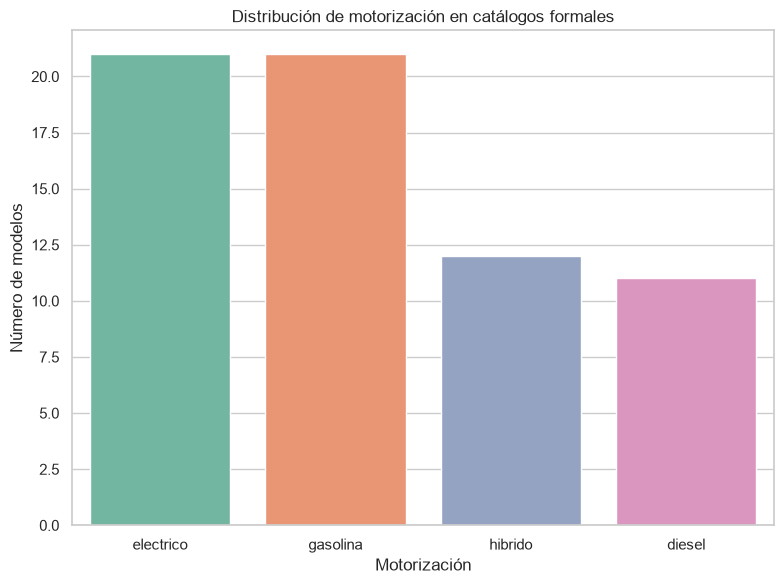

motorizacion
electrico    21
gasolina     21
hibrido      12
diesel       11


In [5]:
# Gráfico: distribución de motorización en catálogos
todos_modelos = []
for e in catalogos:
    for m in e['modelos']:
        todos_modelos.append({'entidad': e['nombre_entidad'], 'motorizacion': m['motorizacion']})
df_mot = pd.DataFrame(todos_modelos)

fig, ax = plt.subplots(figsize=(8, 6))
mot_counts = df_mot['motorizacion'].value_counts()
sns.barplot(x=mot_counts.index, y=mot_counts.values, ax=ax, palette="Set2")
ax.set_title('Distribución de motorización en catálogos formales')
ax.set_xlabel('Motorización')
ax.set_ylabel('Número de modelos')
plt.tight_layout()
plt.savefig(FIG_DIR / "f08_motorizacion_formal.png", dpi=150, bbox_inches="tight")
plt.show()

print(df_mot['motorizacion'].value_counts().to_string())

      entidad  precio_min  precio_max  precio_promedio  n_con_precio
Dongfeng Cuba       15900       99000     34958.823529            34
      BDC ONE       14849       67135     25162.625000            16


C:\Users\jorge\AppData\Local\Temp\ipykernel_15868\2164285168.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_precio, x='entidad', y='precio_promedio', ax=ax, palette="mako")


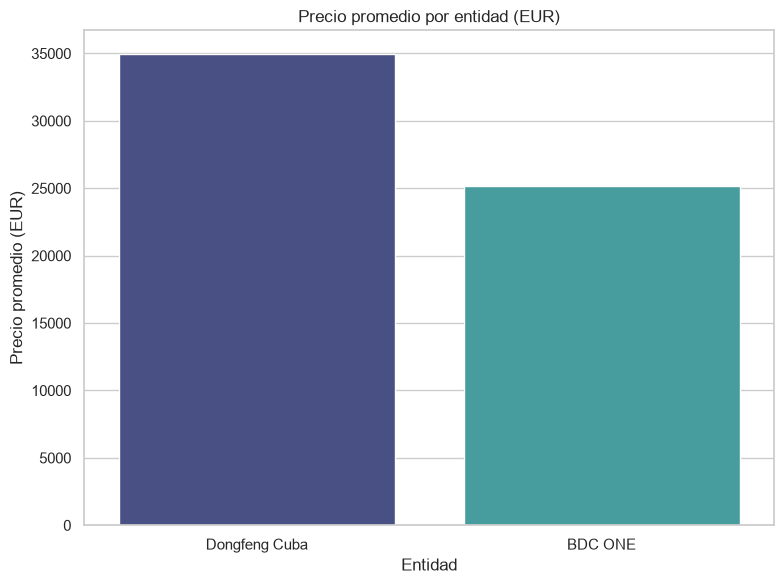

In [6]:
# Gráfico: rango de precios por entidad
datos_precio = []
for e in catalogos:
    if e['modelos']:
        precios = [m['precio_original'] for m in e['modelos'] if m['precio_original']]
        if precios:
            datos_precio.append({
                'entidad': e['nombre_entidad'],
                'precio_min': min(precios),
                'precio_max': max(precios),
                'precio_promedio': sum(precios) / len(precios),
                'n_con_precio': len(precios),
            })
df_precio = pd.DataFrame(datos_precio)
print(df_precio.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=df_precio, x='entidad', y='precio_promedio', ax=ax, palette="mako")
ax.set_title('Precio promedio por entidad (EUR)')
ax.set_xlabel('Entidad')
ax.set_ylabel('Precio promedio (EUR)')
plt.tight_layout()
plt.savefig(FIG_DIR / "f09_precios_formales.png", dpi=150, bbox_inches="tight")
plt.show()

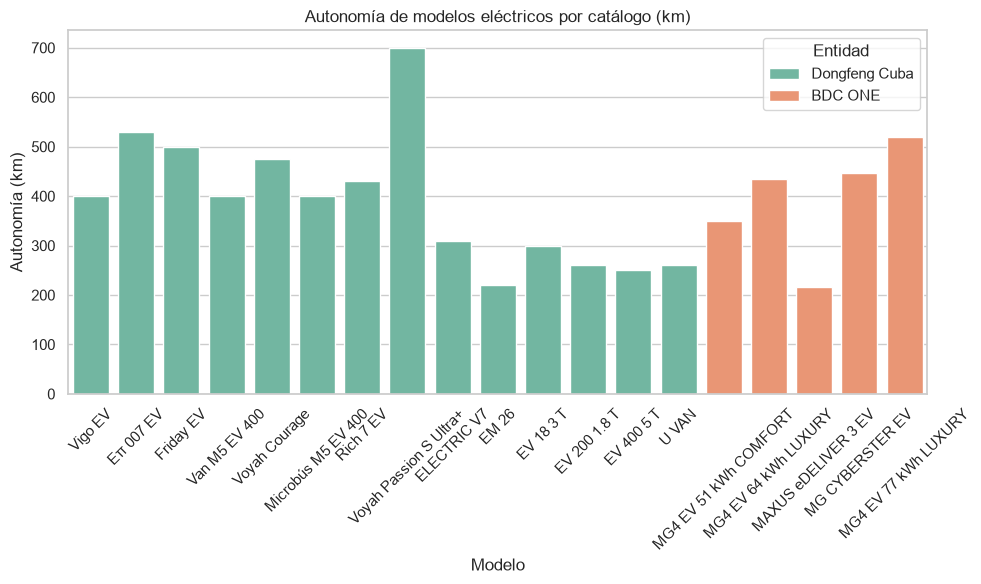

      entidad                 modelo  autonomia_km
Dongfeng Cuba                Vigo EV           400
Dongfeng Cuba              Eπ 007 EV           530
Dongfeng Cuba              Friday EV           500
Dongfeng Cuba          Van M5 EV 400           400
Dongfeng Cuba          Voyah Courage           476
Dongfeng Cuba     Microbús M5 EV 400           400
Dongfeng Cuba              Rich 7 EV           430
Dongfeng Cuba Voyah Passion S Ultra+           700
Dongfeng Cuba            ELECTRIC V7           310
Dongfeng Cuba                  EM 26           220
Dongfeng Cuba              EV 18 3 T           300
Dongfeng Cuba           EV 200 1.8 T           260
Dongfeng Cuba             EV 400 5 T           250
Dongfeng Cuba                  U VAN           260
      BDC ONE  MG4 EV 51 kWh COMFORT           350
      BDC ONE   MG4 EV 64 kWh LUXURY           435
      BDC ONE    MAXUS eDELIVER 3 EV           216
      BDC ONE        MG CYBERSTER EV           446
      BDC ONE   MG4 EV 77 kWh L

In [7]:
# Gráfico: autonomía de modelos eléctricos
ev_autonomia = []
for e in catalogos:
    for m in e['modelos']:
        if m['motorizacion'] == 'electrico' and m.get('autonomia_km'):
            ev_autonomia.append({
                'entidad': e['nombre_entidad'],
                'modelo': m['modelo'],
                'autonomia_km': m['autonomia_km'],
            })
df_ev = pd.DataFrame(ev_autonomia)

if not df_ev.empty:
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=df_ev, x='modelo', y='autonomia_km', hue='entidad', ax=ax, palette="Set2")
    ax.set_title('Autonomía de modelos eléctricos por catálogo (km)')
    ax.set_xlabel('Modelo')
    ax.set_ylabel('Autonomía (km)')
    plt.xticks(rotation=45)
    ax.legend(title='Entidad')
    plt.tight_layout()
    plt.savefig(FIG_DIR / "f09_autonomia_ev.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(df_ev.to_string(index=False))
else:
    print('No hay datos de autonomía para vehículos eléctricos')

## 4. Comparación con el mercado informal

In [8]:
# Cargar datos de Revolico para comparación
anuncios = cargar_json(DATA_PROC / "anuncios_revolico_final.json")
df_rev = pd.DataFrame(anuncios)

print("=== MARCAS EN REVOLICO ===")
print(df_rev['marca'].value_counts().to_string())

print("\n=== MARCAS EN CATÁLOGOS FORMALES ===")
print("Marcas formales registradas en entidades:")
for _, r in df_formal.iterrows():
    marcas_str = ', '.join(r['marcas_comercializadas']) if r['marcas_comercializadas'] else '(ninguna)'
    print('  ' + r['nombre'] + ': ' + marcas_str)

# Verificar qué marcas formales aparecen en Revolico
marcas_rev = set(df_rev['marca'])
print("\nMarcas de Revolico: " + str(sorted(marcas_rev)))
print("Dongfeng aparece en Revolico: " + str('Dongfeng' in marcas_rev))
print("MG aparece en Revolico: " + str('MG' in marcas_rev))
print("Maxus aparece en Revolico: " + str('Maxus' in marcas_rev))
print("Mitsubishi aparece en Revolico: " + str('Mitsubishi' in marcas_rev))

=== MARCAS EN REVOLICO ===
marca
Hyundai     19
Kia          5
Nissan       1
Honda        1
Toyota       1
BMW          1
Dongfeng     1
Geely        1

=== MARCAS EN CATÁLOGOS FORMALES ===
Marcas formales registradas en entidades:
  BDC ONE: MG, Maxus, Mitsubishi
  Dongfeng Cuba: Dongfeng
  MCV Comercial, S.A.: (ninguna)
  Servicios Automotores, S.A. (SASA): (ninguna)
  Empresa Comercializadora DIVEP: (ninguna)
  IMPEXPORT, S.U.R.L.: (ninguna)
  Corporación CIMEX, S.A. División de Transporte Automotor: (ninguna)
  Empresa Importadora PALCO: (ninguna)
  Empresa Central de Abastecimiento y Venta de Equipos de Transporte Pesado y sus Piezas (TRANSIMPORT): (ninguna)
  Empresa Proveedora General del Transporte (TRADEX): (ninguna)

Marcas de Revolico: ['BMW', 'Dongfeng', 'Geely', 'Honda', 'Hyundai', 'Kia', 'Nissan', 'Toyota']
Dongfeng aparece en Revolico: True
MG aparece en Revolico: False
Maxus aparece en Revolico: False
Mitsubishi aparece en Revolico: False


In [9]:
# Comparación de precios
print("\n=== COMPARACIÓN DE PRECIOS ===")
print("Mercado informal (Revolico):")
print("  Precio promedio:", round(df_rev['precio_anuncio'].mean(), 2), "USD")
print("  Precio mediana:", df_rev['precio_anuncio'].median(), "USD")
print("  Rango:", df_rev['precio_anuncio'].min(), "- " + str(df_rev['precio_anuncio'].max()), "USD")

print("\nMercado formal (catálogos, precios en EUR -> USD aprox. 1 EUR = 1.09 USD):")
todos_precios_eur = []
for e in catalogos:
    for m in e['modelos']:
        if m['precio_original']:
            todos_precios_eur.append(m['precio_original'])
if todos_precios_eur:
    print("  Precio promedio:", round(sum(todos_precios_eur) / len(todos_precios_eur), 2), "EUR")
    print("  Rango:", min(todos_precios_eur), "- " + str(max(todos_precios_eur)), "EUR")
    print("  (Nota: precios formales no incluyen impuestos)")


=== COMPARACIÓN DE PRECIOS ===
Mercado informal (Revolico):
  Precio promedio: 31903.33 USD
  Precio mediana: 31000.0 USD
  Rango: 10000 - 100000 USD

Mercado formal (catálogos, precios en EUR -> USD aprox. 1 EUR = 1.09 USD):
  Precio promedio: 31824.04 EUR
  Rango: 14849 - 99000 EUR
  (Nota: precios formales no incluyen impuestos)


## 5. Modelos "A consultar" de Dongfeng

In [10]:
print("=== MODELOS 'A CONSULTAR' DE DONG FENG ===")
sin_precio = []
for e in catalogos:
    if e['id_entidad'] == 'DONGFENG_CUBA':
        for m in e['modelos']:
            if m['precio_original'] is None:
                sin_precio.append(m)

print("Total sin precio:", len(sin_precio))
for m in sin_precio:
    print('  - ' + m['modelo'] + ' | ' + m['tipo_vehiculo'] + ' | ' + m['motorizacion'] + ' | Autonomía: ' + str(m.get('autonomia_km', 'N/A')) + ' km')

=== MODELOS 'A CONSULTAR' DE DONG FENG ===
Total sin precio: 15
  - ELECTRIC V7 | Van | electrico | Autonomía: 310 km
  - EM 26 | Van | electrico | Autonomía: 220 km
  - EV 18 3 T | Camión comercial | electrico | Autonomía: 300 km
  - EV 200 1.8 T | Camión comercial | electrico | Autonomía: 260 km
  - EV 400 5 T | Camión comercial | electrico | Autonomía: 250 km
  - U VAN | Microbús | electrico | Autonomía: 260 km
  - CAPTAIN W | Camión comercial | gasolina | Autonomía: None km
  - MINI VAN CARGO | Van | gasolina | Autonomía: None km
  - MINI VAN PASAJEROS | Microbús | gasolina | Autonomía: None km
  - CAPTAIN 12 T | Camión comercial | diesel | Autonomía: None km
  - CAPTAIN 3,5 T | Camión comercial | diesel | Autonomía: None km
  - CAPTAIN 4,5 T | Camión comercial | diesel | Autonomía: None km
  - CAPTAIN 5,5 T | Camión comercial | diesel | Autonomía: None km
  - CAPTAIN 8-10 T | Camión comercial | diesel | Autonomía: None km
  - CAPTAIN T 4x4 | Camión comercial | diesel | Autonomía: 

## 6. Conclusiones del mercado formal

- Solo **2 de 10 entidades** tienen catálogo público: Dongfeng Cuba y BDC ONE.
- Dongfeng tiene **49 modelos** (16 eléctricos, 12 híbridos, 10 gasolina, 11 diésel).
- BDC ONE tiene **16 modelos** (5 eléctricos, 11 gasolina).
- Los precios formales van desde 14,849 EUR hasta 99,000 EUR (sin impuestos).
- **Dongfeng** aparece tanto en el mercado formal como en el informal (1 anuncio de Dongfeng BOX en Revolico).
- MG, Maxus y Mitsubishi están en el formal pero no aparecen en los anuncios de Revolico analizados.
- 15 modelos de Dongfeng tienen precio "A consultar" (sin precio público).